In [1]:
import csv
import os
import numpy as np
import matplotlib.pyplot as plt
F_MHZ = 5000.0          # 2.4 GHz Wi-Fi. Use 5000-5800 for a 5 GHz survey.
D0 = 1.0                # reference distance d0 = 1 m (the standard choice)
# ----------------------------------------------------------------------
# STEP 1 - Data input: your field readings from the phone app
# ----------------------------------------------------------------------
SAMPLE_CSV = """Distance_m,RSSI1_dBm,RSSI2_dBm
1,-35,-37
2,-42,-40
5,-55,-53
10,-65,-67
15,-72,-70
20,-78,-76
"""
def load_readings(fname="rssi_distance.csv"):
    """Read (distance, [readings...]) rows; create a sample on first run."""
    if not os.path.exists(fname):
        with open(fname, "w") as f:
            f.write(SAMPLE_CSV)
        print(f"[i] No {fname} found - a SAMPLE file was created with the")
        print("    handout's illustrative values. Replace them with your own")
        print("    field readings, then rerun.")
    dists, all_readings = [], []
    with open(fname) as f:
        for row in csv.reader(f):
            if not row or row[0].startswith("Distance"):
                continue                       # skip header / blank lines
            dists.append(float(row[0]))
            all_readings.append([float(v) for v in row[1:] if v.strip()])
    return np.array(dists), all_readings

In [2]:
# ----------------------------------------------------------------------
# STEP 2 - Average the repeat readings (and keep their spread)
# ----------------------------------------------------------------------
def average_readings(all_readings):
    """Mean and spread (std dev) of the repeat readings at each distance."""
    means = np.array([np.mean(r) for r in all_readings])
    spreads = np.array([np.std(r) for r in all_readings])
    return means, spreads

# ----------------------------------------------------------------------
# STEP 3 - Theory: FSPL and the free-space prediction
# ----------------------------------------------------------------------
def fspl_db(d, f_mhz=F_MHZ):
    """Free Space Path Loss in dB (d in metres, f in MHz)."""
    return 20 * np.log10(d) + 20 * np.log10(f_mhz) - 27.55

def free_space_prediction(d, rssi_at_d0):
    """
    Free-space RSSI curve ANCHORED at your own d0 = 1 m measurement:
        RSSI(d) = RSSI(d0) - [FSPL(d) - FSPL(d0)]
                = RSSI(d0) - 20*log10(d/D0)
    Anchoring removes the unknown router transmit power and antenna gains
    from the comparison - only the SHAPE of the decay is being tested.
    """
    return rssi_at_d0 - 20 * np.log10(d / D0)

In [3]:
# ----------------------------------------------------------------------
# STEP 4 - Fit the Log-Distance Path Loss Model: find YOUR n
# ----------------------------------------------------------------------
def fit_path_loss_exponent(dists, rssi_means):
    """
    Log-distance model: RSSI(d) = RSSI(d0) - 10*n*log10(d/d0).
    Rearranged, RSSI is LINEAR in x = 10*log10(d/d0) with slope -n,
    so a least-squares straight-line fit gives n directly.
    Returns (n, rssi_d0_fit, sigma) where sigma is the shadowing spread
    X_sigma - the std dev of the residuals around the fitted line.
    """
    x = 10 * np.log10(dists / D0)
    slope, intercept = np.polyfit(x, rssi_means, 1)
    n = -slope
    residuals = rssi_means - (slope * x + intercept)
    sigma = float(np.std(residuals))
    return n, intercept, sigma

def classify_environment(n):
    if n < 2.2:  return "free-space-like (open, unobstructed)"
    if n < 3.0:  return "lightly obstructed indoor / open corridor"
    if n < 4.0:  return "typical indoor with walls and furniture"
    return "heavily obstructed indoor (many walls / floors)"

In [4]:
# ----------------------------------------------------------------------
# STEP 5 - Report table and figures
# ----------------------------------------------------------------------
def print_table(dists, all_readings, means, theory, fitted):
    n_rd = max(len(r) for r in all_readings)
    hdr = ("Dist (m)  " + "".join(f"R{k+1} (dBm)  " for k in range(n_rd))
           + "Avg (dBm)  Free-space  Fitted model  Extra loss")
    print("\n" + hdr)
    print("-" * len(hdr))
    for i, d in enumerate(dists):
        rd = "".join(f"{v:>8.0f}  " for v in all_readings[i]).ljust(n_rd * 10)
        extra = theory[i] - means[i]        # how far BELOW free space we are
        print(f"{d:>7.0f}  {rd}{means[i]:>8.1f}  {theory[i]:>10.1f}  "
              f"{fitted[i]:>12.1f}  {extra:>9.1f}")

def plot_rssi_vs_distance(dists, means, spreads, n, rssi_d0,
                          fname="rssi_vs_distance.png"):
    d_smooth = np.linspace(dists.min(), dists.max(), 300)
    theory = free_space_prediction(d_smooth, means[0])
    fitted = rssi_d0 - 10 * n * np.log10(d_smooth / D0)
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.errorbar(dists, means, yerr=spreads, fmt="o", color="tab:blue",
                capsize=4, markersize=7, label="Measured (avg \u00b1 spread)")
    ax.plot(d_smooth, theory, "--", color="tab:green", lw=2,
            label="Free space, n = 2 (anchored at 1 m)")
    ax.plot(d_smooth, fitted, "-", color="tab:red", lw=2,
            label=f"Fitted log-distance model, n = {n:.2f}")
    ax.set_xlabel("Distance from router (m)")
    ax.set_ylabel("RSSI (dBm)")
    ax.set_title("Signal strength vs distance: measurement, free-space "
                 "theory, fitted model")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    return fig

def plot_semilog(dists, means, spreads, n, rssi_d0,
                 fname="rssi_vs_log_distance.png"):
    d_smooth = np.linspace(dists.min(), dists.max(), 300)
    fitted = rssi_d0 - 10 * n * np.log10(d_smooth / D0)

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.errorbar(dists, means, yerr=spreads, fmt="o", color="tab:blue",
                capsize=4, markersize=7, label="Measured (avg \u00b1 spread)")
    ax.plot(d_smooth, fitted, "-", color="tab:red", lw=2,
            label=f"Fitted line, slope = -10n = {-10*n:.1f} dB/decade")
    ax.set_xscale("log")
    ax.set_xticks(dists)
    ax.set_xticklabels([f"{d:g}" for d in dists])
    ax.set_xlabel("Distance from router (m) - log scale")
    ax.set_ylabel("RSSI (dBm)")
    ax.set_title("The same data on a log-distance axis: the decay "
                 "becomes a straight line")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    return fig


=== RSSI vs distance survey (f = 5000 MHz) ===

Dist (m)  R1 (dBm)  R2 (dBm)  Avg (dBm)  Free-space  Fitted model  Extra loss
-----------------------------------------------------------------------------
      1       -35       -37     -36.0       -36.0         -33.5        0.0
      2       -42       -40     -41.0       -42.0         -43.2       -1.0
      5       -55       -53     -54.0       -50.0         -56.0        4.0
     10       -65       -67     -66.0       -56.0         -65.7       10.0
     15       -72       -70     -71.0       -59.5         -71.3       11.5
     20       -78       -76     -77.0       -62.0         -75.4       15.0

Absolute FSPL at 1 m and 5000 MHz: 46.4 dB
Implied router EIRP (RSSI at 1 m + FSPL at 1 m): 10.4 dBm

Fitted path loss exponent  n = 3.22
Shadowing spread       sigma = 1.73 dB
Environment classification : typical indoor with walls and furniture
Rule-of-thumb check: doubling distance costs 9.7 dB here (free space: 6.0 dB)

Saved: rssi_vs_dist

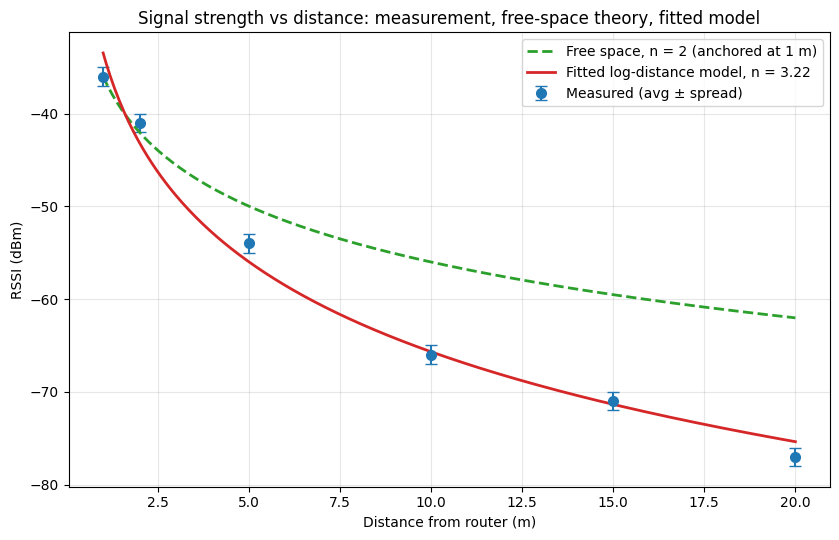

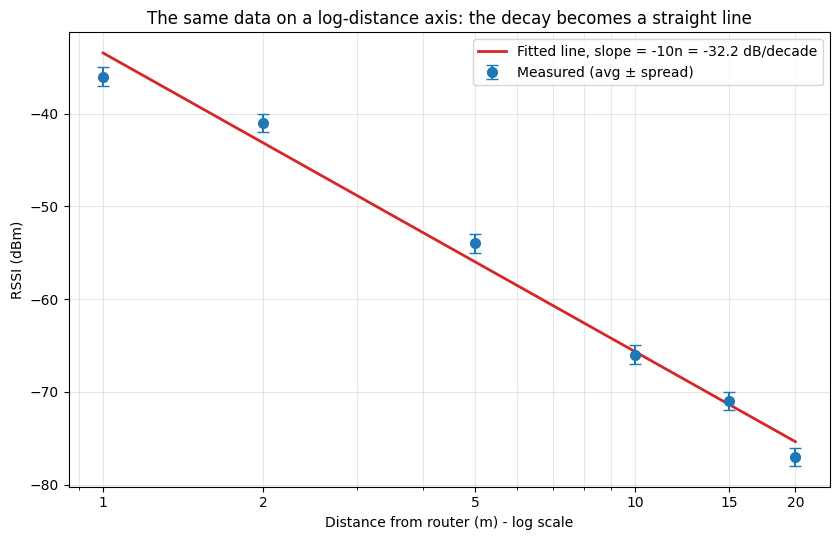

In [5]:
# ----------------------------------------------------------------------
# MAIN - run the whole analysis
# ----------------------------------------------------------------------
if __name__ == "__main__":
    dists, all_readings = load_readings()
    means, spreads = average_readings(all_readings)
    # theory curve at the measurement distances (anchored at d0 = 1 m)
    theory = free_space_prediction(dists, means[0])
    # fit the log-distance model
    n, rssi_d0_fit, sigma = fit_path_loss_exponent(dists, means)
    fitted = rssi_d0_fit - 10 * n * np.log10(dists / D0)
    print("\n=== RSSI vs distance survey (f = %.0f MHz) ===" % F_MHZ)
    print_table(dists, all_readings, means, theory, fitted)
    print(f"\nAbsolute FSPL at 1 m and {F_MHZ:.0f} MHz: "
          f"{fspl_db(1.0):.1f} dB")
    print(f"Implied router EIRP (RSSI at 1 m + FSPL at 1 m): "
          f"{means[0] + fspl_db(1.0):.1f} dBm")
    print(f"\nFitted path loss exponent  n = {n:.2f}")
    print(f"Shadowing spread       sigma = {sigma:.2f} dB")
    print(f"Environment classification : {classify_environment(n)}")
    print(f"Rule-of-thumb check: doubling distance costs "
          f"{10 * n * np.log10(2):.1f} dB here (free space: 6.0 dB)")
    plot_rssi_vs_distance(dists, means, spreads, n, rssi_d0_fit)
    plot_semilog(dists, means, spreads, n, rssi_d0_fit)
    print("\nSaved: rssi_vs_distance.png, rssi_vs_log_distance.png")
    plt.show()